In [7]:
import pandas as pd
df = pd.read_csv("/Users/irynaoleinikova/Documents/Ironhack/Ironhack_labs/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [9]:
# What are the most popular product categories on Amazon UK?
# Frequency of each product category 
category_counts = df['category'].value_counts()
category_counts.head(10)  # Top 10


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

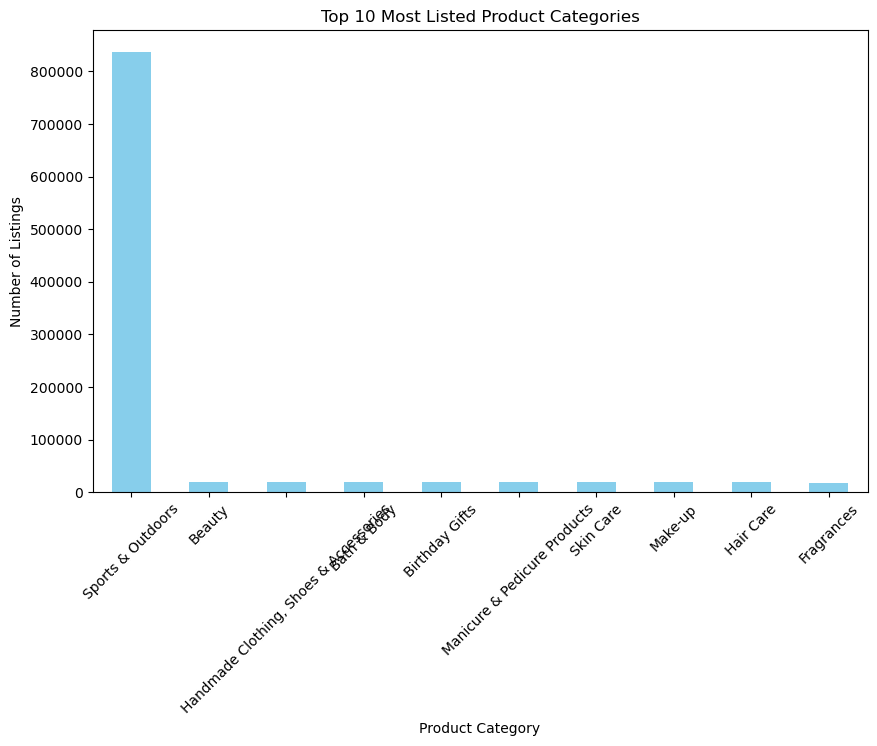

In [10]:
import matplotlib.pyplot as plt

top_categories = category_counts.head(10)
plt.figure(figsize=(10,6))
top_categories.plot(kind='bar', color='skyblue')
plt.title('Top 10 Most Listed Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45)
plt.show()


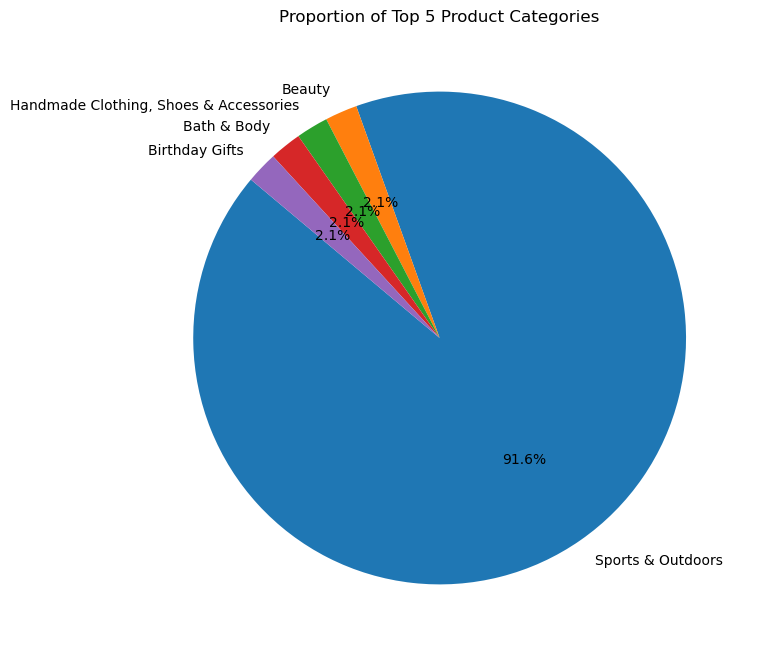

In [11]:
top_5 = category_counts.head(5)
plt.figure(figsize=(8,8))
top_5.plot(kind='pie', autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Top 5 Product Categories')
plt.ylabel('')
plt.show()


In [13]:
#How are products priced on Amazon UK?
#Central Tendencies
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean: £{mean_price:.2f}")
print(f"Median: £{median_price:.2f}")
print(f"Mode: £{mode_price:.2f}")


Mean: £89.24
Median: £19.09
Mode: £9.99


In [14]:
#Measures of Dispersion
price_range = df['price'].max() - df['price'].min()
std_dev = df['price'].std()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)
variance = df['price'].var()

print(f"Range: £{price_range:.2f}")
print(f"Standard Deviation: £{std_dev:.2f}")
print(f"IQR: £{iqr:.2f}")
print(f"Variance: {variance:.2f}")


Range: £100000.00
Standard Deviation: £345.61
IQR: £36.00
Variance: 119445.49


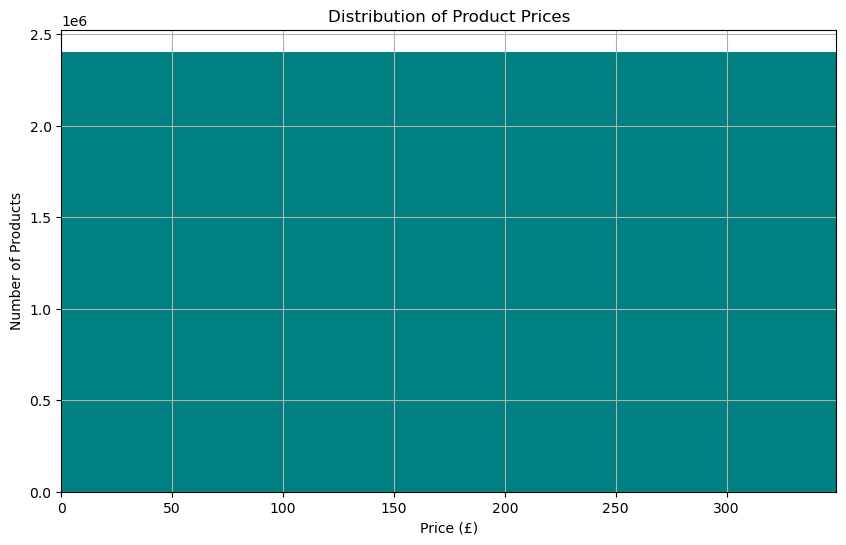

In [15]:
#Price Distribution
plt.figure(figsize=(10,6))
df['price'].hist(bins=100, color='teal')
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.xlim(0, df['price'].quantile(0.95))  # To handle outliers
plt.show()


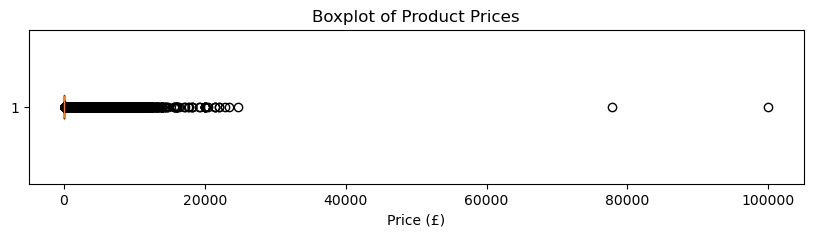

In [16]:
#Price Outliers
plt.figure(figsize=(10,2))
plt.boxplot(df['price'], vert=False)
plt.title('Boxplot of Product Prices')
plt.xlabel('Price (£)')
plt.show()


In [19]:
#How do customers rate products on Amazon UK?
#Central Tendencies
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

print(f"Mean: {mean_rating:.2f}")
print(f"Median: {median_rating:.2f}")
print(f"Mode: {mode_rating}")


Mean: 2.15
Median: 0.00
Mode: 0.0


In [21]:
#Measures of Dispertion
std_rating = df['stars'].std()
var_rating = df['stars'].var()
iqr_rating = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print(f"Standard Deviation: {std_rating:.2f}")
print(f"Variance: {var_rating:.2f}")
print(f"IQR: {iqr_rating:.2f}")


Standard Deviation: 2.19
Variance: 4.82
IQR: 4.40


In [23]:
#Shape of Distribution
from scipy.stats import skew, kurtosis

rating_skewness = skew(df['stars'].dropna())
rating_kurtosis = kurtosis(df['stars'].dropna())

print(f"Skewness: {rating_skewness:.2f}")
print(f"Kurtosis: {rating_kurtosis:.2f}")


Skewness: 0.08
Kurtosis: -1.93


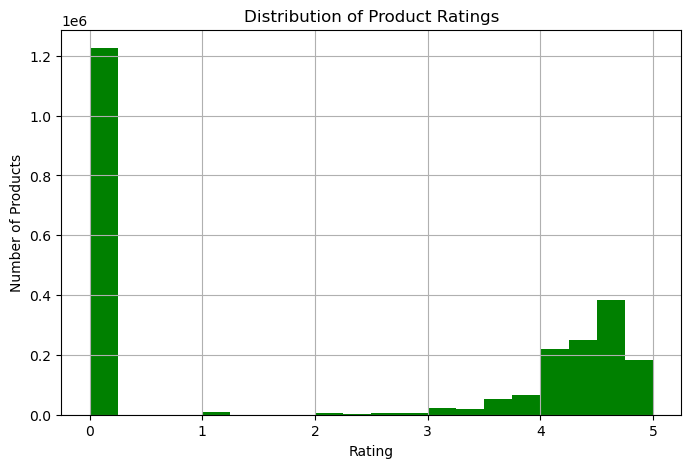

In [26]:
plt.figure(figsize=(8,5))
df['stars'].hist(bins=20, color='green')
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Products')
plt.show()


Insights Summary

### Part 1: Product Categories
- The most listed product category is Sports & Outdoors with 836,265 listings, far ahead of others.
- The next most common categories are:
  - Beauty – 19,312 listings
  - Handmade Clothing, Shoes & Accessories – 19,229 listings
- Sports & Outdoors completely dominates the listings, suggesting a high demand and/or oversaturation in that category. This could indicate a competitive market where businesses need stronger differentiation.

### Part 2: Pricing
- The average product price is £89.24, but the most common price is just £9.99, and the median is £19.09.
- This shows a right-skewed distribution, meaning a small number of high-priced products are raising the average.
- Price dispersion is significant:
  - Standard Deviation: £345.61
  - Range: £100,000.00 (likely driven by outliers)
  - IQR (Interquartile Range): £36.00
- Most products are priced in the lower range, with a few very expensive items skewing the overall view. These outliers should be accounted for in pricing strategy and inventory planning.


### Part 3: Ratings
- The average rating is 2.15, with a mode and median of 0.0 — indicating that a large portion of products may not have any ratings yet.
- Dispersion in ratings:
  - Standard Deviation: 2.19
  - Variance: 4.82
  - IQR: 4.40
- This shows high variability, and likely many new or unrated listings.
- Insights suggest that while some products are well-rated, a large portion lacks customer engagement, which may impact trust and conversions. Businesses might need to invest in review generation and early-stage marketing.
